In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  
from scipy.ndimage import minimum_filter
from scipy.optimize import least_squares

np.set_printoptions(precision=6, suppress=True)


def modified_gradient_method(f, grad, x0, gamma0=0.1, tol=1e-8, max_iter=20000):
    """Steepest descent with an adaptive step length gamma: gamma is grown
    (x1.2) after every accepted (decreasing) step and halved whenever a
    step fails to decrease f. Stops when the function value changes by
    less than tol between successive accepted iterates."""
    x = np.array(x0, dtype=float)
    fx = f(x)
    gamma = gamma0
    for k in range(1, max_iter + 1):
        g = grad(x)
        while True:
            x_new = x - gamma * g
            fx_new = f(x_new)
            if fx_new < fx:
                break
            gamma *= 0.5
            if gamma < 1e-16:
                return x, fx, k, False
        if abs(fx_new - fx) < tol:
            return x_new, fx_new, k, True
        x, fx = x_new, fx_new
        gamma *= 1.2
    return x, fx, max_iter, False


def newton_minimize(f, grad, hess, x0, tol=1e-8, max_iter=1000):
    """Newton's method for unconstrained minimization: x_{k+1} = x_k - H(x_k)^-1 grad(x_k)."""
    x = np.array(x0, dtype=float)
    fx = f(x)
    for k in range(1, max_iter + 1):
        g = grad(x)
        H = hess(x)
        try:
            step = np.linalg.solve(H, g)
        except np.linalg.LinAlgError:
            step = np.linalg.lstsq(H, g, rcond=None)[0]
        x_new = x - step
        if not np.all(np.isfinite(x_new)):
            return x, fx, k, False
        fx_new = f(x_new)
        if abs(fx_new - fx) < tol:
            return x_new, fx_new, k, True
        x, fx = x_new, fx_new
    return x, fx, max_iter, False


def bfgs_minimize(f, grad, x0, gamma_grid=None, tol=1e-8, max_iter=1000):
    """BFGS quasi-Newton method. The step length along each search direction
    is chosen by a grid search with resolution 0.01 (as requested by the
    exercise) instead of an analytic line search."""
    if gamma_grid is None:
        gamma_grid = np.arange(0.01, 2.01, 0.01)
    n = len(x0)
    x = np.array(x0, dtype=float)
    Hinv = np.eye(n)
    fx = f(x)
    g = grad(x)
    for k in range(1, max_iter + 1):
        if np.linalg.norm(g) < 1e-14:
            return x, fx, k, True
        d = -Hinv @ g
        f_trials = np.array([f(x + gam * d) for gam in gamma_grid])
        best = np.argmin(f_trials)
        gamma, fx_new = gamma_grid[best], f_trials[best]
        x_new = x + gamma * d
        g_new = grad(x_new)
        s = x_new - x
        y = g_new - g
        sy = s @ y
        if sy > 1e-12:
            rho = 1.0 / sy
            I = np.eye(n)
            Hinv = (I - rho * np.outer(s, y)) @ Hinv @ (I - rho * np.outer(y, s)) + rho * np.outer(s, s)
        if abs(fx_new - fx) < tol:
            return x_new, fx_new, k, True
        x, fx, g = x_new, fx_new, g_new
    return x, fx, max_iter, False


def compare_methods(f, grad, hess, initial_guesses, gamma0=0.1, tol=1e-8, gamma_grid=None, mg_max_iter=20000):
    """Run all three minimization methods from each initial guess and print
    a comparison table of the solution found, its function value, and the
    number of iterations required."""
    header = f"{'x0':>16} | {'method':>18} | {'x*':>24} | {'f(x*)':>13} | {'iters':>6} | converged"
    print(header)
    print("-" * len(header))
    results = {}
    for x0 in initial_guesses:
        res_mg = modified_gradient_method(f, grad, x0, gamma0=gamma0, tol=tol, max_iter=mg_max_iter)
        res_nt = newton_minimize(f, grad, hess, x0, tol=tol)
        res_bf = bfgs_minimize(f, grad, x0, gamma_grid=gamma_grid, tol=tol)
        results[x0] = {"modified gradient": res_mg, "Newton": res_nt, "BFGS": res_bf}
        x0_str = "(" + ", ".join(f"{float(v):.3g}" for v in x0) + ")"
        for name, res in results[x0].items():
            x_star, f_star, n_it, conv = res
            x_star_str = "[" + ", ".join(f"{float(v):.5g}" for v in x_star) + "]"
            print(f"{x0_str:>16} | {name:>18} | {x_star_str:>24} | {f_star:13.4e} | {n_it:6d} | {conv}")
    return results


# Exercise 1

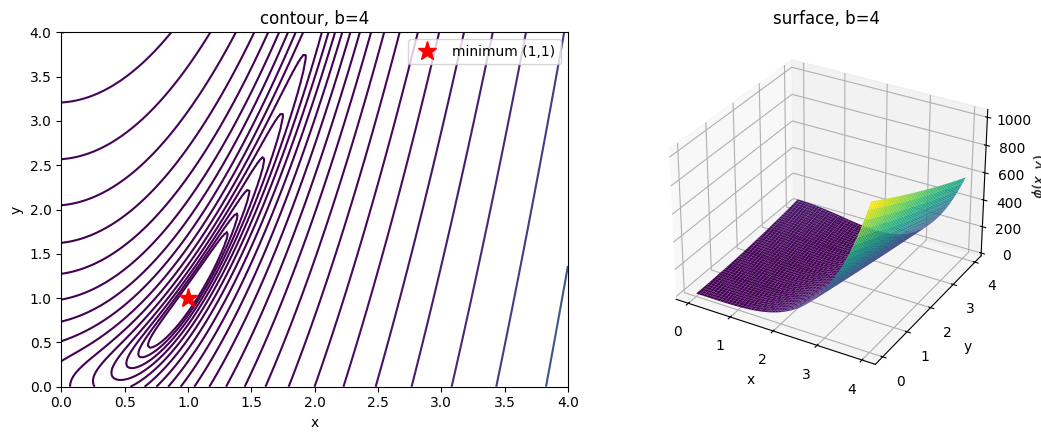


=== b = 4 ===
              x0 |             method |                       x* |         f(x*) |  iters | converged
-----------------------------------------------------------------------------------------------------
          (0, 0) |  modified gradient |       [0.99935, 0.99855] |    5.1390e-07 |    280 | True
          (0, 0) |             Newton |                   [1, 1] |    0.0000e+00 |      3 | True
          (0, 0) |               BFGS |                   [1, 1] |    3.3761e-17 |      8 | True
          (2, 2) |  modified gradient |        [0.9993, 0.99862] |    4.8379e-07 |    318 | True
          (2, 2) |             Newton |                   [1, 1] |    4.9304e-32 |      6 | True
          (2, 2) |               BFGS |                   [1, 1] |    2.1778e-14 |      8 | True
          (1, 3) |  modified gradient |         [1.0012, 1.0024] |    1.4746e-06 |    463 | True
          (1, 3) |             Newton |                   [1, 1] |    0.0000e+00 |      2 | True
     

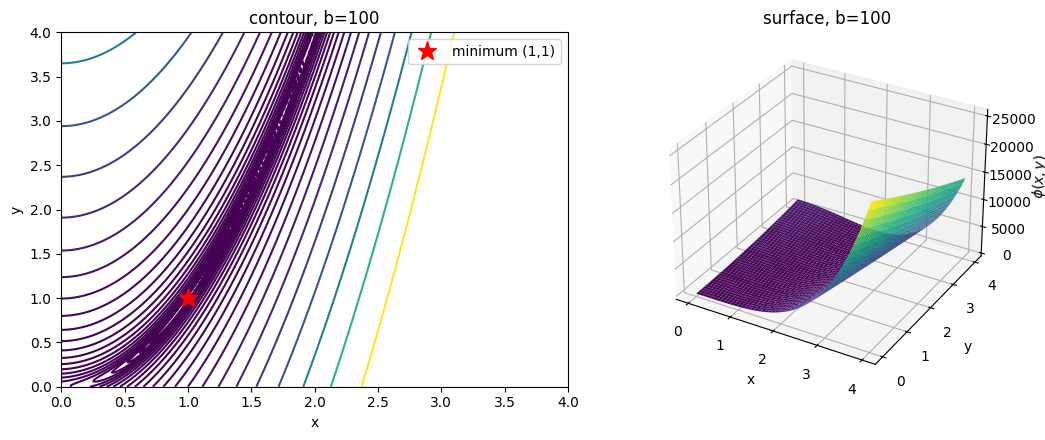


=== b = 100 ===
              x0 |             method |                       x* |         f(x*) |  iters | converged
-----------------------------------------------------------------------------------------------------
          (0, 0) |  modified gradient |       [0.99056, 0.98112] |    9.0025e-05 |   3387 | True
          (0, 0) |             Newton |                   [1, 1] |    0.0000e+00 |      3 | True
          (0, 0) |               BFGS |                   [1, 1] |    1.3430e-16 |     17 | True
          (2, 2) |  modified gradient |         [1.0266, 1.0542] |    7.1413e-04 |   4920 | True
          (2, 2) |             Newton |                   [1, 1] |    8.3323e-30 |      5 | True
          (2, 2) |               BFGS |                   [1, 1] |    4.6594e-14 |     81 | True
          (1, 3) |  modified gradient |         [1.0217, 1.0439] |    4.7311e-04 |   7612 | True
          (1, 3) |             Newton |                   [1, 1] |    0.0000e+00 |      2 | True
   

In [7]:
def rosenbrock(xy, a=1.0, b=4.0):
    x, y = xy
    return (a - x) ** 2 + b * (y - x ** 2) ** 2

def rosenbrock_grad(xy, a=1.0, b=4.0):
    x, y = xy
    dx = -2 * (a - x) - 4 * b * x * (y - x ** 2)
    dy = 2 * b * (y - x ** 2)
    return np.array([dx, dy])

def rosenbrock_hess(xy, a=1.0, b=4.0):
    x, y = xy
    dxx = 2 - 4 * b * y + 12 * b * x ** 2
    dxy = -4 * b * x
    dyy = 2 * b
    return np.array([[dxx, dxy], [dxy, dyy]])

xg = np.linspace(0, 4, 200)
yg = np.linspace(0, 4, 200)
Xg, Yg = np.meshgrid(xg, yg)
initial_guesses1 = [(0.0, 0.0), (2.0, 2.0), (1.0, 3.0), (3.0, 1.0)]

for b in (4.0, 100.0):
    Zg = (1.0 - Xg) ** 2 + b * (Yg - Xg ** 2) ** 2

    fig = plt.figure(figsize=(11, 4.5))
    ax1 = fig.add_subplot(1, 2, 1)
    ax1.contour(Xg, Yg, Zg, levels=np.logspace(-1, 3.5, 25))
    ax1.plot(1, 1, 'r*', markersize=14, label='minimum (1,1)')
    ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_title(f'contour, b={b:g}')
    ax1.legend()

    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    ax2.plot_surface(Xg, Yg, Zg, cmap='viridis', linewidth=0, antialiased=True)
    ax2.set_xlabel('x'); ax2.set_ylabel('y'); ax2.set_zlabel(r'$\phi(x,y)$')
    ax2.set_title(f'surface, b={b:g}')
    plt.tight_layout()
    plt.show()

    print(f"\n=== b = {b:g} ===")
    f_b = lambda xy: rosenbrock(xy, b=b)
    g_b = lambda xy: rosenbrock_grad(xy, b=b)
    h_b = lambda xy: rosenbrock_hess(xy, b=b)
    compare_methods(f_b, g_b, h_b, initial_guesses1, gamma0=0.1, tol=1e-8, mg_max_iter=30000)

# Exercise 2

basins located from the plot/grid scan (x, y, phi):
[[   -5.561404    -0.052632 -1010.466826]
 [    5.385965    -0.052632  -791.410689]]


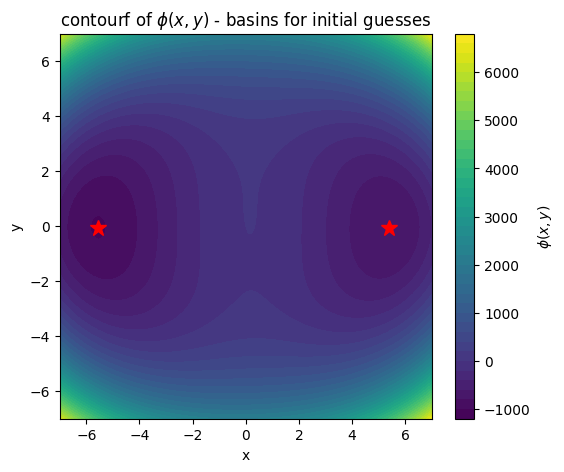

              x0 |             method |                       x* |         f(x*) |  iters | converged
-----------------------------------------------------------------------------------------------------
         (-5, 0) |  modified gradient |     [-5.5586, -0.043067] |   -1.0105e+03 |     15 | True
         (-5, 0) |             Newton |     [-5.5586, -0.043067] |   -1.0105e+03 |      5 | True
         (-5, 0) |               BFGS |     [-5.5586, -0.043067] |   -1.0105e+03 |      8 | True
          (5, 0) |  modified gradient |       [5.3917, -0.04596] |   -7.9142e+02 |     12 | True
          (5, 0) |             Newton |       [5.3917, -0.04596] |   -7.9142e+02 |      5 | True
          (5, 0) |               BFGS |       [5.3917, -0.04596] |   -7.9142e+02 |      7 | True
          (0, 0) |  modified gradient |     [-5.5586, -0.043067] |   -1.0105e+03 |     15 | True
          (0, 0) |             Newton |       [5.3917, -0.04596] |   -7.9142e+02 |     62 | True
          (0, 0) |  

{(-5.0,
  0.0): {'modified gradient': (array([-5.558566, -0.043067]),
   np.float64(-1010.4732048085039),
   15,
   True), 'Newton': (array([-5.558566, -0.043067]),
   np.float64(-1010.4732048085037),
   5,
   True), 'BFGS': (array([-5.558566, -0.043067]),
   np.float64(-1010.4732048085039),
   8,
   True)},
 (5.0,
  0.0): {'modified gradient': (array([ 5.39171, -0.04596]),
   np.float64(-791.4168021175618),
   12,
   True), 'Newton': (array([ 5.39171, -0.04596]),
   np.float64(-791.4168021175619),
   5,
   True), 'BFGS': (array([ 5.39171, -0.04596]),
   np.float64(-791.4168021175623),
   7,
   True)},
 (0.0,
  0.0): {'modified gradient': (array([-5.558566, -0.043067]),
   np.float64(-1010.4732048085035),
   15,
   True), 'Newton': (array([ 5.39171, -0.04596]),
   np.float64(-791.4168021175618),
   62,
   True), 'BFGS': (array([-5.558566, -0.043067]),
   np.float64(-1010.4732048085039),
   11,
   True)},
 (-3.0,
  3.0): {'modified gradient': (array([-5.558567, -0.043067]),
   np.float6

In [8]:
def phi2(xy):
    x, y = xy
    return (x ** 2 + y ** 2) ** 2 - 15 * (4 * x ** 2 + (y / 2) ** 2) + 20 * x + 5 * y

def phi2_grad(xy):
    x, y = xy
    dx = 4 * x * (x ** 2 + y ** 2) - 120 * x + 20
    dy = 4 * y * (x ** 2 + y ** 2) - 7.5 * y + 5
    return np.array([dx, dy])

def phi2_hess(xy):
    x, y = xy
    dxx = 12 * x ** 2 + 4 * y ** 2 - 120
    dxy = 8 * x * y
    dyy = 4 * x ** 2 + 12 * y ** 2 - 7.5
    return np.array([[dxx, dxy], [dxy, dyy]])

xg2 = np.linspace(-7, 7, 400)
yg2 = np.linspace(-7, 7, 400)
Xg2, Yg2 = np.meshgrid(xg2, yg2)
Zg2 = phi2([Xg2, Yg2])

plt.figure(figsize=(6, 5))
cf = plt.contourf(Xg2, Yg2, Zg2, levels=40, cmap='viridis')
plt.colorbar(cf, label=r'$\phi(x,y)$')
plt.xlabel('x'); plt.ylabel('y')
plt.title(r'contourf of $\phi(x,y)$ - basins for initial guesses')

mask = minimum_filter(Zg2, size=25) == Zg2
basins = np.column_stack([Xg2[mask], Yg2[mask], Zg2[mask]])
basins = basins[np.argsort(basins[:, 2])]
print("basins located from the plot/grid scan (x, y, phi):")
print(basins)

for bx, by, _ in basins:
    plt.plot(bx, by, 'r*', markersize=12)
plt.show()

initial_guesses2 = [(-5.0, 0.0), (5.0, 0.0), (0.0, 0.0), (-3.0, 3.0), (3.0, -3.0), (-6.0, -4.0)]
compare_methods(phi2, phi2_grad, phi2_hess, initial_guesses2, gamma0=0.1, tol=1e-12, mg_max_iter=50000)

# Exercise 3

## Part 1: fitting f to noisy data - `scipy.optimize.least_squares` vs. the modified gradient method

In [9]:
np.random.seed(0)

def h_true(z):
    return z ** 3 + z ** 2 - 1

z = np.arange(1.0, 3.0 + 1e-9, 0.01)
noise_std = 0.5
b_data = h_true(z) + np.random.normal(0.0, noise_std, size=z.shape)

def residual(x, z=z, b=b_data):
    x1, x2, x3 = x
    return z ** x1 + z ** x2 + x3 - b

def jacobian(x, z=z):
    x1, x2, x3 = x
    logz = np.log(z)
    J = np.empty((z.size, 3))
    J[:, 0] = z ** x1 * logz
    J[:, 1] = z ** x2 * logz
    J[:, 2] = 1.0
    return J

def lsq_cost(x):
    r = residual(x)
    return 0.5 * r @ r

def lsq_grad(x):
    return jacobian(x).T @ residual(x)

x0_lsq = np.array([1.0, 1.0, 1.0])

sol = least_squares(residual, x0_lsq)
print("scipy.optimize.least_squares:")
print(f"  x = {sol.x}, cost = {0.5 * sol.fun @ sol.fun:.4f}, nfev = {sol.nfev}")

x_mg, f_mg, it_mg, conv_mg = modified_gradient_method(lsq_cost, lsq_grad, x0_lsq, gamma0=1e-4, tol=1e-10, max_iter=200000)
print(f"\nmodified gradient method from x0 = {x0_lsq}:")
print(f"  x = {x_mg}, cost = {f_mg:.4f}, iters = {it_mg}, converged = {conv_mg}")

x0_lsq_pert = np.array([1.0, 1.05, 1.0])
x_mg2, f_mg2, it_mg2, conv_mg2 = modified_gradient_method(lsq_cost, lsq_grad, x0_lsq_pert, gamma0=1e-4, tol=1e-10, max_iter=200000)
print(f"\nmodified gradient method from a symmetry-broken x0 = {x0_lsq_pert}:")
print(f"  x = {x_mg2}, cost = {f_mg2:.4f}, iters = {it_mg2}, converged = {conv_mg2}")

scipy.optimize.least_squares:
  x = [ 2.015708  2.991407 -0.947034], cost = 26.0304, nfev = 21

modified gradient method from x0 = [1. 1. 1.]:
  x = [ 2.626047  2.626047 -1.167593], cost = 27.7635, iters = 1616, converged = True

modified gradient method from a symmetry-broken x0 = [1.   1.05 1.  ]:
  x = [ 2.015392  2.991515 -0.946826], cost = 26.0304, iters = 7569, converged = True


## Part 2: Gauss-Newton, Levenberg-Marquardt, and the final fit

Gauss-Newton from x0 = [1. 1. 1.]: converged = False after 1 iteration(s) (x = [1. 1. 1.])

Levenberg-Marquardt from the same x0 = [1. 1. 1.]: converged = True after 62 iterations (x = [ 2.991407  2.015708 -0.947034])

From a symmetry-broken initial datum x0 = [ 2.8  1.8 -0.7], both converge:
  Gauss-Newton:        x = [ 2.991407  2.015708 -0.947034], iters = 8, converged = True
  Levenberg-Marquardt: x = [ 2.991407  2.015708 -0.947034], iters = 7, converged = True


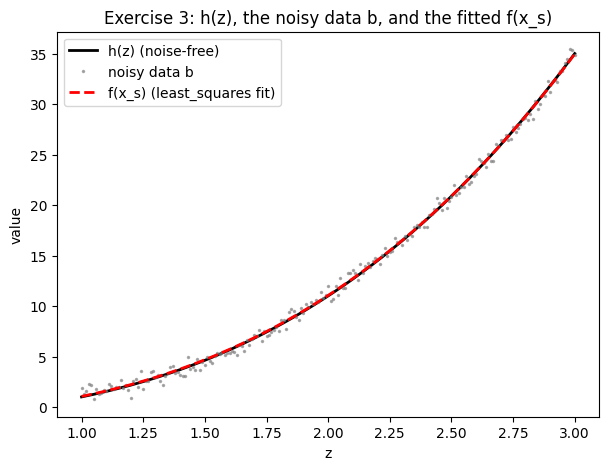

In [10]:
def gauss_newton(residual_fn, jacobian_fn, x0, tol=1e-10, max_iter=200):
    x = np.array(x0, dtype=float)
    for k in range(1, max_iter + 1):
        r = residual_fn(x)
        J = jacobian_fn(x)
        try:
            delta = np.linalg.solve(J.T @ J, J.T @ r)
        except np.linalg.LinAlgError:
            return x, k, False
        x_new = x - delta
        if not np.all(np.isfinite(x_new)) or np.linalg.norm(x_new) > 1e8:
            return x_new, k, False
        if np.linalg.norm(delta) < tol:
            return x_new, k, True
        x = x_new
    return x, max_iter, False


def levenberg_marquardt(residual_fn, jacobian_fn, x0, lam0=1e-2, tol=1e-8, max_iter=200):
    """Gauss-Newton with a damping term lambda*I added to J^T J: lambda
    shrinks after every accepted step (behaving like Gauss-Newton close to
    convergence) and grows after a rejected one (behaving like a small
    gradient step, which is far more robust far from the solution)."""
    x = np.array(x0, dtype=float)
    lam = lam0
    r = residual_fn(x)
    cost = 0.5 * r @ r
    for k in range(1, max_iter + 1):
        J = jacobian_fn(x)
        g = J.T @ r
        if np.linalg.norm(g) < tol:
            return x, k, True
        A = J.T @ J + lam * np.eye(len(x))
        step = np.linalg.solve(A, g)
        if np.linalg.norm(step) < 1e-13:
            return x, k, True
        x_trial = x - step
        r_trial = residual_fn(x_trial)
        cost_trial = 0.5 * r_trial @ r_trial
        if np.isfinite(cost_trial) and cost_trial < cost:
            x, r, cost = x_trial, r_trial, cost_trial
            lam = max(lam * 0.5, 1e-12)
        else:
            lam *= 2.0
            if lam > 1e12:
                return x, k, False
    return x, max_iter, False


x_gn0, it_gn0, conv_gn0 = gauss_newton(residual, jacobian, x0_lsq)
print(f"Gauss-Newton from x0 = {x0_lsq}: converged = {conv_gn0} after {it_gn0} iteration(s) (x = {x_gn0})")

x_lm0, it_lm0, conv_lm0 = levenberg_marquardt(residual, jacobian, x0_lsq)
print(f"\nLevenberg-Marquardt from the same x0 = {x0_lsq}: converged = {conv_lm0} "
      f"after {it_lm0} iterations (x = {x_lm0})")

x0_good = np.array([2.8, 1.8, -0.7])
x_gn, it_gn, conv_gn = gauss_newton(residual, jacobian, x0_good)
x_lm, it_lm, conv_lm = levenberg_marquardt(residual, jacobian, x0_good)
print(f"\nFrom a symmetry-broken initial datum x0 = {x0_good}, both converge:")
print(f"  Gauss-Newton:        x = {x_gn}, iters = {it_gn}, converged = {conv_gn}")
print(f"  Levenberg-Marquardt: x = {x_lm}, iters = {it_lm}, converged = {conv_lm}")

x_s = sol.x
plt.figure(figsize=(7, 5))
plt.plot(z, h_true(z), 'k-', linewidth=2, label='h(z) (noise-free)')
plt.plot(z, b_data, '.', color='gray', markersize=3, alpha=0.6, label='noisy data b')
plt.plot(z, z ** x_s[0] + z ** x_s[1] + x_s[2], 'r--', linewidth=2, label='f(x_s) (least_squares fit)')
plt.xlabel('z'); plt.ylabel('value')
plt.legend()
plt.title('Exercise 3: h(z), the noisy data b, and the fitted f(x_s)')
plt.show()
